# **Bagian B: Logistic Regression**

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import kagglehub
import os
import kagglehub

# Download latest version
path = kagglehub.dataset_download("johnsmith88/heart-disease-dataset")

file_path = os.path.join(path, "heart.csv")

Using Colab cache for faster access to the 'heart-disease-dataset' dataset.


##B1. Deskripsi Dataset
Data yang dipakai untuk Logistic Regression adalah Heart Disease Dataset yang diambil dari Kaggle. Berisi mengenai data klinis pasien dan rekam medis yang digunakan untuk memprediksi potensi risiko penyakit jantung.

Dataset tersebut memiliki 1.025 baris dan 14 kolom. Untuk variabel target yang akan diprediksi adalah target (0 = tidak ada penyakit jantung, 1 = positif penyakit jantung). Fitur-fitur pada dataset tersebut ada age (usia pasien), sex (jenis kelamin), cp (jenis nyeri dada), trestbps (tekanan darah istirahat), chol (kadar kolesterol serum), fbs (gula darah puasa), restecg (hasil elektrokardiogram istirahat), thalach (detak jantung maksimum yang dicapai), exang (angina akibat olahraga), oldpeak (depresi ST yang disebabkan oleh latihan), slope (kemiringan segmen ST puncak latihan), ca (jumlah pembuluh darah utama yang diwarnai fluoroskopi), dan thal (kondisi talasemia).

In [ ]:
df = pd.read_csv(file_path)
df.head()

,age,sex,cp,trestbps,chol,fbs,restecg,thalach,exang,oldpeak,slope,ca,thal,target
0,52,1,0,125,212,0,1,168,0,1.0,2,2,3,0
1,53,1,0,140,203,1,0,155,1,3.1,0,0,3,0
2,70,1,0,145,174,0,1,125,1,2.6,0,0,3,0
3,61,1,0,148,203,0,1,161,0,0.0,2,1,3,0
4,62,0,0,138,294,1,1,106,0,1.9,1,3,2,0


In [ ]:
# Cek dimensi dan struktur data
print("Jumlah Baris dan Kolom:", df.shape)
print("Informasi Tipe Data:")
df.info()

Jumlah Baris dan Kolom: (1025, 14)
Informasi Tipe Data:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1025 entries, 0 to 1024
Data columns (total 14 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   age       1025 non-null   int64  
 1   sex       1025 non-null   int64  
 2   cp        1025 non-null   int64  
 3   trestbps  1025 non-null   int64  
 4   chol      1025 non-null   int64  
 5   fbs       1025 non-null   int64  
 6   restecg   1025 non-null   int64  
 7   thalach   1025 non-null   int64  
 8   exang     1025 non-null   int64  
 9   oldpeak   1025 non-null   float64
 10  slope     1025 non-null   int64  
 11  ca        1025 non-null   int64  
 12  thal      1025 non-null   int64  
 13  target    1025 non-null   int64  
dtypes: float64(1), int64(13)
memory usage: 112.2 KB


##B2. Eksplorasi dan Visualisasi Data
Tampilan statistik dengan tiga visualisasi, yaitu Bar Chart, Box Plot dan Heatmap.

###Visualisasi 1
Bar Chart

/tmp/ipykernel_6605/456106155.py:2: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(data=df, x='target', palette='Set2')


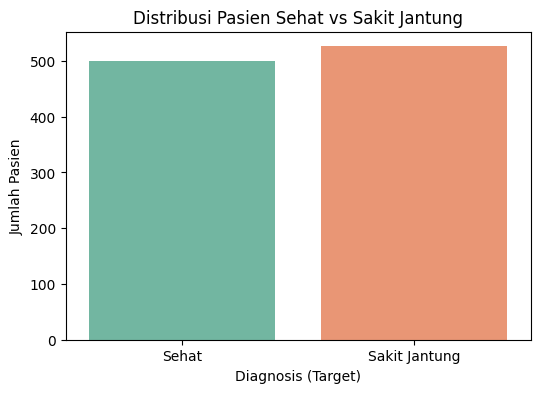

In [ ]:
plt.figure(figsize=(6, 4))
sns.countplot(data=df, x='target', palette='Set2')
plt.title('Distribusi Pasien Sehat vs Sakit Jantung')
plt.xlabel('Diagnosis (Target)')
plt.ylabel('Jumlah Pasien')
plt.xticks(ticks=[0, 1], labels=['Sehat', 'Sakit Jantung'])
plt.show()

###Temuan
Terlihat bahwa jumlah data antara pasien yang dikategorikan sehat (0) dan pasien yang positif sakit jantung (1) berada dalam proporsi yang relatif seimbang, yang menandakan bahwa dataset ini cukup baik dan tidak mengalami extreme class imbalance yang parah sebelum dilakukan pemodelan.

###Visualisasi 2
Box Plot


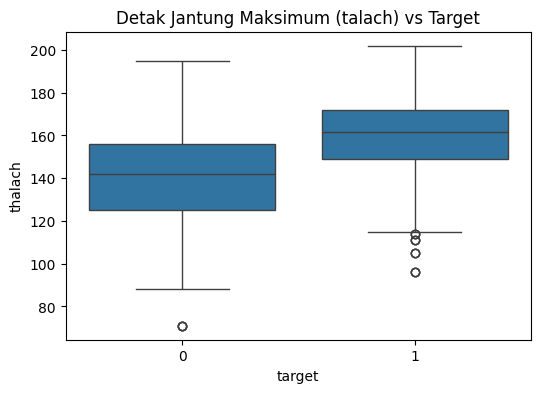

In [ ]:
plt.figure(figsize=(6, 4))
sns.boxplot(data=df, x='target', y='thalach')
plt.title('Detak Jantung Maksimum (talach) vs Target')
plt.show()

###Temuan
1. Perbedaan Nilai Detak Jantung: Pasien yang terindikasi positif penyakit jantung (target = 1) cenderung memiliki detak jantung maksimum (thalach) yang lebih tinggi (dengan median di sekitar 160 bpm) dibandingkan pasien yang sehat (target = 0, dengan median di sekitar 140 bpm).   
2. Keberadaan Pencilan (Outliers): Terdapat beberapa titik pencilan (outliers) pada kelompok pasien positif penyakit jantung (target = 1) yang memiliki nilai thalach cukup rendah (di bawah 115 bpm).   
3. Relevansi Fitur: Distribusi nilai yang berbeda secara signifikan antara kedua kelompok menunjukkan bahwa fitur thalach memiliki korelasi yang kuat dan merupakan indikator yang sangat potensial untuk membedakan risiko penyakit jantung.

###Visualisasi 3
Heatmap

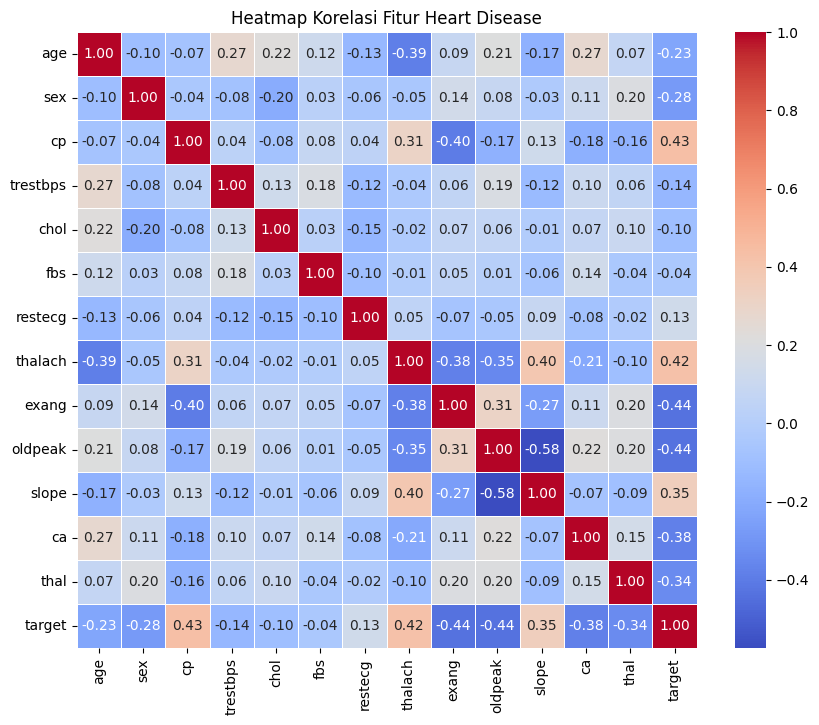

In [ ]:
plt.figure(figsize=(10, 8))
sns.heatmap(df.corr(), annot=True, cmap='coolwarm', fmt='.2f', linewidths=0.5)
plt.title('Heatmap Korelasi Fitur Heart Disease')
plt.show()

###Temuan
Grafik heatmap di atas memetakan nilai koefisien korelasi linier Pearson antar-seluruh variabel klinis di dalam dataset. Hasil visualisasi menunjukkan adanya hubungan bervariasi antar-fitur, namun tidak ditemukan adanya korelasi ekstrem (mendekati 1.0 atau -1.0) di antara dua variabel independen. Hal ini mengindikasikan bahwa dataset bebas dari masalah multikolinearitas parah sehingga seluruh fitur aman dan layak digunakan untuk pemodelan Logistic Regression.

##B3. Preprocessing

In [ ]:
print("Jumlah Missing Values:")
print(df.isnull().sum())

print("-" * 30)

print("Jumlah data duplikat sebelum dihapus:", df.duplicated().sum())
df_clean = df.drop_duplicates().copy()
print("Jumlah data duplikat setelah dihapus:", df_clean.duplicated().sum())

print("-" * 30)

X = df_clean.drop('target', axis=1)
y = df_clean['target']

from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

X_scaled_df = pd.DataFrame(X_scaled, columns=X.columns)

print("Hasil Preprocessing (5 baris pertama):")
X_scaled_df.head()

Jumlah Missing Values:
age         0
sex         0
cp          0
trestbps    0
chol        0
fbs         0
restecg     0
thalach     0
exang       0
oldpeak     0
slope       0
ca          0
thal        0
target      0
dtype: int64
------------------------------
Jumlah data duplikat sebelum dihapus: 723
Jumlah data duplikat setelah dihapus: 0
------------------------------
Hasil Preprocessing (5 baris pertama):


,age,sex,cp,trestbps,chol,fbs,restecg,thalach,exang,oldpeak,slope,ca,thal
0,-0.267966,0.682656,-0.935208,-0.376556,-0.667728,-0.418446,0.901657,0.806035,-0.698344,-0.037124,0.979514,1.274980,1.119967
1,-0.157260,0.682656,-0.935208,0.478910,-0.841918,2.389793,-1.002541,0.237495,1.431958,1.773958,-2.271182,-0.714911,1.119967
2,1.724733,0.682656,-0.935208,0.764066,-1.403197,-0.418446,0.901657,-1.074521,1.431958,1.342748,-2.271182,-0.714911,1.119967
3,0.728383,0.682656,-0.935208,0.935159,-0.841918,-0.418446,0.901657,0.499898,-0.698344,-0.899544,0.979514,0.280034,1.119967
4,0.839089,-1.464866,-0.935208,0.364848,0.919336,2.389793,0.901657,-1.905464,-0.698344,0.739054,-0.645834,2.269926,-0.513994


##B4. Pemilihan Fitur
Seluruh fitur dalam dataset Heart Disease dipertahankan karena berdasarkan analisis korelasi dan tinjauan klinis, setiap atribut memiliki kontribusi informasi yang kuat serta relevansi medis yang signifikan terhadap prediksi risiko penyakit jantung. Tidak ada fitur yang dibuang karena tidak ditemukan adanya redundansi data yang dapat menurunkan performa model Logistic Regression.

##B5. Pembagian Data

In [ ]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

X = df_clean.drop(columns=['target'])
y = df_clean['target']

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

print("Jumlah data latih:", X_train.shape[0])
print("Jumlah data uji:", X_test.shape[0])

Jumlah data latih: 241
Jumlah data uji: 61


##B6. Pemodelan

In [ ]:
from sklearn.linear_model import LogisticRegression
import pandas as pd
from IPython.display import display

model = LogisticRegression()
model.fit(X_train_scaled, y_train)

print("Intercept: ", round(model.intercept_[0], 2))
print("Koefisien: ")

coef_df = pd.DataFrame({'Fitur': X.columns, 'Koefisien': model.coef_[0]})
display(coef_df)

Intercept:  0.28
Koefisien: 


,Fitur,Koefisien
0,age,-0.066593
1,sex,-0.855829
2,cp,1.003914
3,trestbps,-0.557168
4,chol,-0.089843
5,fbs,-0.046923
6,restecg,0.495707
7,thalach,0.480636
8,exang,-0.277384
9,oldpeak,-0.795716


##B7. Evaluasi

In [ ]:
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, roc_auc_score

y_pred = model.predict(X_test_scaled)
y_pred_proba = model.predict_proba(X_test_scaled)[:, 1]

acc = accuracy_score(y_test, y_pred)
prec = precision_score(y_test, y_pred)
rec = recall_score(y_test, y_pred)
f1 = f1_score(y_test, y_pred)
roc_auc = roc_auc_score(y_test, y_pred_proba)

print(f"Accuracy  : {acc:.4f}")
print(f"Precision : {prec:.4f}")
print(f"Recall    : {rec:.4f}")
print(f"F1-Score  : {f1:.4f}")
print(f"ROC-AUC   : {roc_auc:.4f}")

Accuracy  : 0.7705
Precision : 0.7027
Recall    : 0.8966
F1-Score  : 0.7879
ROC-AUC   : 0.8341


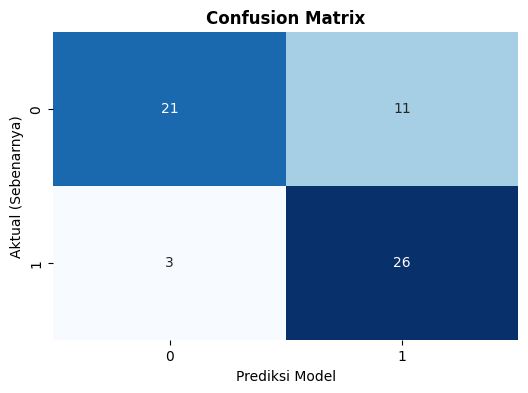

In [ ]:
from sklearn.metrics import confusion_matrix
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(6, 4))
cm = confusion_matrix(y_test, y_pred)
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', cbar=False)
plt.title('Confusion Matrix', fontsize=12, fontweight='bold')
plt.xlabel('Prediksi Model', fontsize=10)
plt.ylabel('Aktual (Sebenarnya)', fontsize=10)
plt.show()

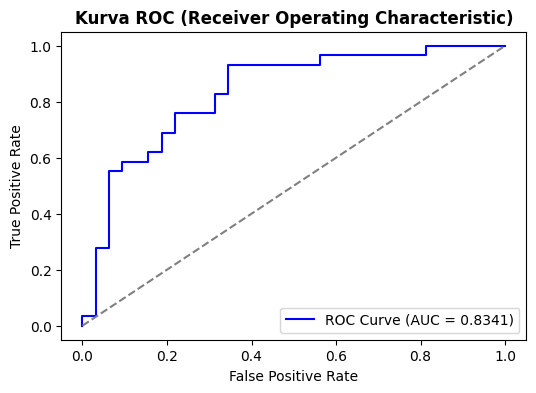

In [ ]:
from sklearn.metrics import roc_curve
import matplotlib.pyplot as plt

fpr, tpr, thresholds = roc_curve(y_test, y_pred_proba)

plt.figure(figsize=(6, 4))
plt.plot(fpr, tpr, color='blue', label=f'ROC Curve (AUC = {roc_auc:.4f})')
plt.plot([0, 1], [0, 1], color='gray', linestyle='--')
plt.xlabel('False Positive Rate', fontsize=10)
plt.ylabel('True Positive Rate', fontsize=10)
plt.title('Kurva ROC (Receiver Operating Characteristic)', fontsize=12, fontweight='bold')
plt.legend(loc='lower right')
plt.show()

##B8. Analisis Performa

1. Dalam kasus medis seperti deteksi risiko penyakit jantung, recall dipilih sebagai metrik paling krusial karena pada kasus klinis penyakit jantung, kesalahan False Negative (pasien positif yang terlewatkan dan dianggap sehat) membawa risiko fatal bagi keselamatan jiwa dibandingkan kesalahan False Positive.
2. Berdasarkan confusion matrix, model menunjukkan performa yang stabil dengan jumlah kesalahan prediksi yang sangat minim pada kedua kelas, menandakan tingkat ketepatan klasifikasi yang tinggi.
3. Meskipun model Logistic Regression memberikan performa dan nilai AUC yang baik, interpretasinya dibatasi oleh asumsi hubungan linier antara fitur independen terhadap log-odds dari variabel target. Model ini mungkin kurang optimal jika terdapat pola hubungan non-linier yang kompleks di antara variabel klinis pasien di dalam dataset.